# Duplicate clips, and what they do to per-class F1

Is any WLASL clip in the data more than once? Each `video_id` is its own file (see
[WLASL_info.md](../../info/WLASL_info.md)), but the same video can be filed under two
`video_id`s, with different glosses or in different sets. This notebook finds those copies,
and asks whether the glosses they touch score worse.

Method: two clips are copies if their files are byte-identical (MD5). A re-encode of the same
video hashes differently, so this is a lower bound. Each copy is one of:

* **a label conflict**: a twin under a different gloss, so the model cannot be right on both;
* **a leak**: a twin with the same gloss in a different set, so a test clip may be in train.

The F1 analysis reuses `MViTv2_S` exp000 on WLASL-2000, as in
[correlation_f1.ipynb](../satnac_2026/correlation_f1.ipynb). Helpers are in
[duplicates.py](./duplicates.py).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from scipy.stats import kendalltau, mannwhitneyu

from src.configs import get_class_list
from src.results import STASH_DIR_NAME, get_asset_path, get_out_stub, load_json
from src.results.dataset_analysis.duplicates import class_duplicate_table, flag_twins
from src.run_types import LABEL_SUFFIX, LABELS_PATH, RESULTS_DIR, SPLIT_DIR
from src.visualise2 import (
    plot_bar_chart,
    plot_metric_correlation,
    save_fig,
    set_thesis_style,
)

set_thesis_style()

split_stems = ["asl100", "asl300", "asl1000", "asl2000"]
md5_stash_p = Path(STASH_DIR_NAME) / "clip_md5.json"
project_name = "dataset_analysis"


def load_instances(split: str) -> pd.DataFrame:
    """Every instance of a split's annotation file, one row each (`set` is train/val/test)."""
    glosses = json.loads((SPLIT_DIR / f"{split}.json").read_text())
    return pd.DataFrame(
        [
            {
                "video_id": i["video_id"],
                "gloss": g["gloss"],
                "set": i["split"],
                "source": i["source"],
                "signer_id": i["signer_id"],
                "variation_id": i["variation_id"],
            }
            for g in glosses
            for i in g["instances"]
        ]
    )


instances = load_instances("asl2000")  # the other splits are subsets of it
len(instances)

21095

## Hash every clip

2 GB of video, about a minute with threads. Run once on the training server, then comment out.

In [2]:
# from src.results import stash_json
# from src.results.dataset_analysis.duplicates import hash_clips
#
# stash_json(hash_clips(RAW_DIR, instances.video_id), md5_stash_p)

In [3]:
instances["md5"] = instances.video_id.map(load_json(md5_stash_p))
assert instances.md5.notna().all()
print(f"{len(instances)} instances, {instances.md5.nunique()} distinct files")

21095 instances, 20010 distinct files


## How many instances are copies, per split

Twins are looked for within each split's own instances, so a smaller split only counts the copies
that are both in it. `label conflict` is a twin under a different gloss; `leak` is a twin with the
same gloss in a different set.

In [4]:
rows = []
for stem in split_stems:
    sub = instances[instances.video_id.isin(load_instances(stem).video_id)]
    flagged = flag_twins(sub)
    test = flagged[flagged.set == "test"]
    rows.append(
        {
            "split": stem,
            "instances": len(flagged),
            "with a twin": int(flagged.has_twin.sum()),
            "label conflict": int(flagged.twin_other_gloss.sum()),
            "twin in another set": int(flagged.twin_other_set.sum()),
            "leak": int(flagged.twin_same_gloss_other_set.sum()),
            "test instances": len(test),
            "test with a twin in train/val": int(test.twin_other_set.sum()),
            "test label conflict": int(test.twin_other_gloss.sum()),
            "test leak": int(test.twin_same_gloss_other_set.sum()),
        }
    )
summary = pd.DataFrame(rows).set_index("split")
summary

,instances,with a twin,label conflict,twin in another set,leak,test instances,test with a twin in train/val,test label conflict,test leak
split,,,,,,,,,
asl100,2038,36,12,16,14,258,1,2,1
asl300,5118,91,41,56,34,668,12,9,3
asl1000,13174,563,469,309,56,1876,62,57,9
asl2000,21095,1985,1877,998,68,2879,184,180,14


In [5]:
flagged = flag_twins(instances)
share = pd.DataFrame(
    {
        "instances": flagged.groupby("set").size(),
        "with a twin %": 100 * flagged.groupby("set").has_twin.mean(),
        "label conflict %": 100 * flagged.groupby("set").twin_other_gloss.mean(),
        "leak %": 100 * flagged.groupby("set").twin_same_gloss_other_set.mean(),
    }
)
share.round(2)

,instances,with a twin %,label conflict %,leak %
set,,,,
test,2879,6.60,6.25,0.49
train,14296,10.10,9.54,0.20
val,3920,8.95,8.49,0.64


## Which glosses collide

Each row is a set of glosses that share a clip, with how many distinct clips are filed under
exactly that set. The `before` / `former` / `past` ambiguity in
[WLASL_info.md](../../info/WLASL_info.md) is the same problem.

In [6]:
conflicts = flagged[flagged.twin_other_gloss]
collisions = conflicts.groupby("md5").gloss.agg(lambda g: " / ".join(sorted(set(g)))).value_counts()
print(f"{len(collisions)} distinct gloss sets over {conflicts.md5.nunique()} clips")
display(collisions.head(15).rename("clips").to_frame())
collisions[collisions.index.str.contains(r"\b(?:before|former|past)\b")]

523 distinct gloss sets over 846 clips


,clips
gloss,
doctor / physician,5
mom / mother,5
freeway / highway,5
hurry / rush,5
story / tale,5
exchange / trade,5
england / english,4
bye / goodbye,4
mine / my,4


gloss
ago / before / last / past    3
ago / before / past           1
before / past                 1
Name: count, dtype: int64

In [7]:
by_source = pd.DataFrame(
    {
        "instances": flagged.groupby("source").size(),
        "with a twin": flagged.groupby("source").has_twin.sum(),
    }
).assign(share=lambda d: 100 * d["with a twin"] / d.instances)
by_source.sort_values("with a twin", ascending=False).round(1)

,instances,with a twin,share
source,,,
signingsavvy,2668,960,36.0
aslsearch,1875,376,20.1
asldeafined,1833,284,15.5
signschool,1968,251,12.8
aslu,1828,54,3.0
handspeak,2211,38,1.7
aslpro,1736,12,0.7
elementalasl,170,6,3.5
spreadthesign,1586,4,0.3


## Per-class F1 against duplicates

Per-class test F1 of `MViTv2_S` exp000 on WLASL-2000 (stashed by
[correlation_f1.ipynb](../satnac_2026/correlation_f1.ipynb); the model trained on the
`asl2000_cutoff_9` labels, which lack 3 short clips and none of them is in the test set).

Two ways to measure how much a gloss is affected, as in the plan:

1. **Flag**: the gloss is in any label conflict.
2. **Fraction**: the share of its instances that are affected, in train, in test, or overall.

In [8]:
f1_stash_p = RESULTS_DIR / "satnac_2026" / STASH_DIR_NAME / "asl2000_cutoff_9_MViTv2_S_exp000_results.json"
classes = get_class_list()
cls_rep = load_json(f1_stash_p)["cls_report"]
f1 = pd.Series(
    {classes[int(k)]: v["f1-score"] for k, v in cls_rep.items() if k.isdigit()}, name="f1"
).rename_axis("gloss")
train_counts = flagged[flagged.set == "train"].groupby("gloss").size().rename("train_instances")

per_class = class_duplicate_table(flagged).join(f1, how="inner").join(train_counts)
assert len(per_class) == len(f1) == 2000
print(f"{int(per_class.conflict_flag.sum())} of {len(per_class)} glosses are in a label conflict")
per_class.sort_values("conflict_all", ascending=False).head(10).round(3)

849 of 2000 glosses are in a label conflict


,conflict_all,twin_all,conflict_train,conflict_test,leak_test,conflict_flag,f1,train_instances
gloss,,,,,,,,
put off,0.857,0.857,1.000,0.0,0.0,True,0.0,5
freeway,0.714,0.714,0.800,0.0,0.0,True,0.0,5
trip,0.714,0.714,0.600,1.0,1.0,True,0.0,5
precipitation,0.714,0.714,0.800,0.0,0.0,True,0.0,5
soul,0.714,0.714,0.800,1.0,0.0,True,0.0,5
sprint,0.714,0.714,0.800,0.0,0.0,True,0.0,5
host,0.714,0.714,0.800,0.0,0.0,True,0.0,5
her,0.636,0.636,0.714,0.0,0.0,True,0.0,7
physician,0.625,0.625,0.600,1.0,0.0,True,0.0,5


### Flag: glosses in a label conflict, against the rest

,glosses,mean F1,median F1,median train instances
in a label conflict,849.0,0.194,0.0,6.0
not,1151.0,0.393,0.4,7.0


Mann-Whitney U p = 7.6e-31


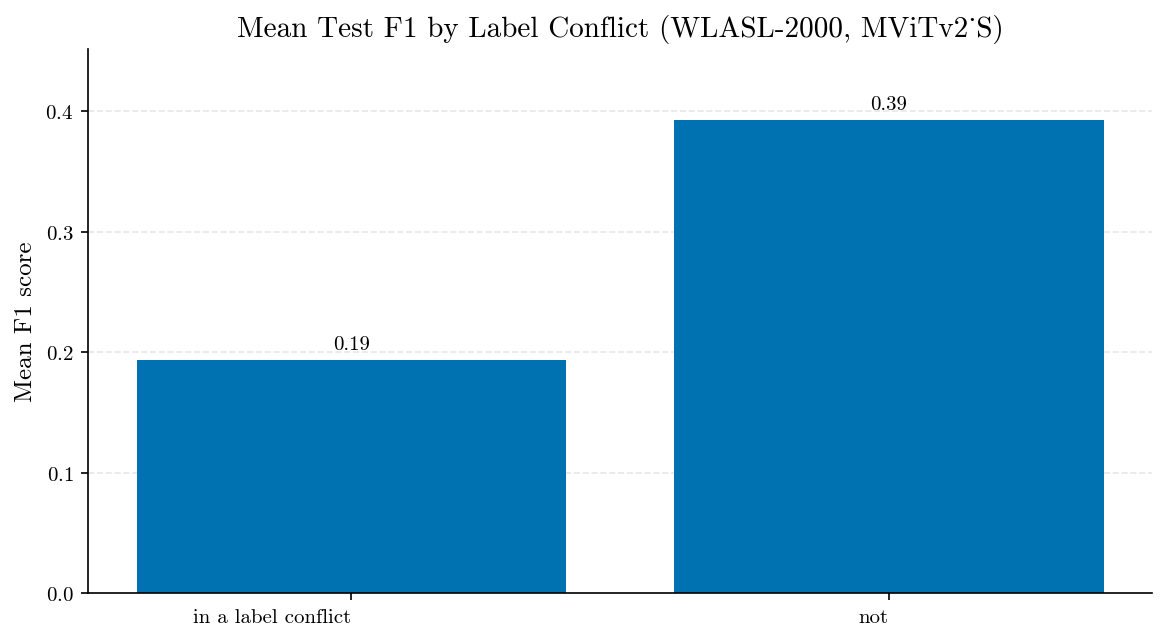

In [9]:
groups = {"in a label conflict": per_class[per_class.conflict_flag], "not": per_class[~per_class.conflict_flag]}
comparison = pd.DataFrame(
    {
        name: {
            "glosses": len(g),
            "mean F1": g.f1.mean(),
            "median F1": g.f1.median(),
            "median train instances": g.train_instances.median(),
        }
        for name, g in groups.items()
    }
).T
u = mannwhitneyu(groups["in a label conflict"].f1, groups["not"].f1)
display(comparison.round(3))
print(f"Mann-Whitney U p = {u.pvalue:.2g}")

fig, ax = plot_bar_chart(
    list(groups),
    [g.f1.mean() for g in groups.values()],
    title="Mean Test F1 by Label Conflict (WLASL-2000, MViTv2_S)",
    ylabel="Mean F1 score",
    rotation=0,
)
stub = get_out_stub("asl2000_cutoff_9_1_indexed", "MViTv2_S", "exp000")
save_fig(fig, get_asset_path("f1_by_label_conflict", stub, project_name))
plt.show()

### Fraction: Kendall's tau of F1 against each share

Many glosses have a share of 0, so the plots show a column at 0 and tau accounts for the ties.
`train_instances` is included as a reference, since F1 also depends on class size (see
[correlation_f1.ipynb](../satnac_2026/correlation_f1.ipynb)).

In [10]:
measures = ["conflict_all", "conflict_train", "conflict_test", "leak_test", "twin_all", "train_instances"]
taus = pd.DataFrame(
    {
        m: dict(zip(("tau", "p"), kendalltau(per_class[m], per_class.f1)))
        | {"glosses with share > 0": int((per_class[m] > 0).sum())}
        for m in measures
    }
).T
taus.round(4)

,tau,p,glosses with share > 0
conflict_all,-0.2490,0.0000,849.0
conflict_train,-0.2337,0.0000,756.0
conflict_test,-0.1303,0.0000,165.0
leak_test,0.0735,0.0004,14.0
twin_all,-0.2335,0.0000,880.0
train_instances,0.2522,0.0000,2000.0


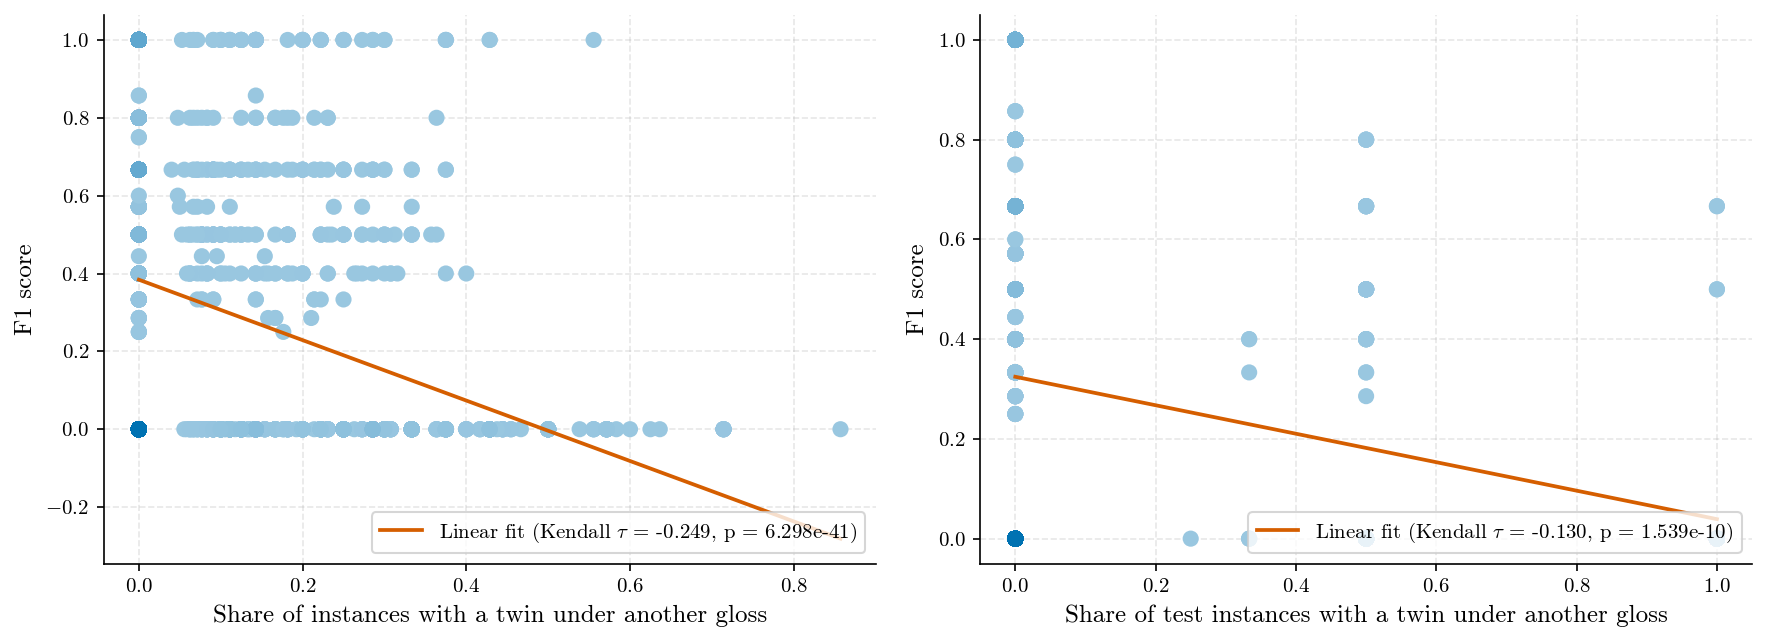

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (measure, label) in zip(
    axes,
    [("conflict_all", "Share of instances with a twin under another gloss"), ("conflict_test", "Share of test instances with a twin under another gloss")],
):
    plot_metric_correlation(per_class[measure], per_class.f1, xlabel=label, shade_by_density=True, ax=ax)
fig.tight_layout()
save_fig(fig, get_asset_path("f1_vs_label_conflict_share", stub, project_name))
plt.show()

### Is it just class size?

F1 rises with class size, and a gloss in a conflict could simply be a smaller one. Within bins of
train instances, F1 of glosses in a conflict against the rest:

In [12]:
bins = pd.qcut(per_class.train_instances, 4, duplicates="drop")
per_class.groupby([bins, "conflict_flag"], observed=True).f1.agg(["size", "mean"]).unstack().round(3)

size         mean       
conflict_flag   False True   False  True 
train_instances                          
(4.999, 7.0]      768   601  0.333  0.144
(7.0, 8.0]        103    70  0.465  0.220
(8.0, 30.0]       280   178  0.531  0.353

## Test instances: right, wrong, or the twin's gloss

For each test instance (in the order the model scored them), whether the prediction was right,
and for instances with a twin under another gloss, whether the model predicted that other gloss (0 by definition where there is no conflict).

In [13]:
test_labels = pd.read_json(
    LABELS_PATH / "asl2000_cutoff_9_1_indexed" / f"test_{LABEL_SUFFIX}", dtype={"video_id": str}
)
scored = load_json(f1_stash_p)
assert test_labels.label_num.tolist() == scored["all_targets"]  # same order as the predictions
test = test_labels[["video_id"]].assign(
    gloss=[classes[t] for t in scored["all_targets"]],
    predicted=[classes[p] for p in scored["all_preds"]],
)
test["correct"] = test.gloss == test.predicted
test = test.merge(flagged[["video_id", "md5", "has_twin", "twin_other_gloss", "twin_same_gloss_other_set"]])
glosses_of_clip = flagged.groupby("md5").gloss.agg(set)
test["twin_glosses"] = test.md5.map(glosses_of_clip)
test["predicted_a_twin_gloss"] = [
    conflict and pred in glosses and pred != gloss
    for conflict, pred, glosses, gloss in zip(test.twin_other_gloss, test.predicted, test.twin_glosses, test.gloss)
]
kind = test.twin_other_gloss.map({True: "twin under another gloss", False: "no label conflict"})
by_kind = test.groupby(kind).agg(
    instances=("correct", "size"), accuracy=("correct", "mean"), predicted_a_twin_gloss=("predicted_a_twin_gloss", "mean")
)
display(by_kind.round(3))
print(
    f"test accuracy {test.correct.mean():.3f} overall, "
    f"{test[~test.twin_other_gloss].correct.mean():.3f} without the label conflicts"
)

,instances,accuracy,predicted_a_twin_gloss
twin_other_gloss,,,
no label conflict,2699,0.411,0.000
twin under another gloss,180,0.061,0.878


test accuracy 0.389 overall, 0.411 without the label conflicts


In [14]:
leaks = test[test.twin_same_gloss_other_set]
print(f"{len(leaks)} test instances have a same-gloss twin in train/val: accuracy {leaks.correct.mean():.3f}")
other_test = test[~test.twin_same_gloss_other_set & ~test.twin_other_gloss]
print(f"{len(other_test)} test instances with no twin of either kind: accuracy {other_test.correct.mean():.3f}")

14 test instances have a same-gloss twin in train/val: accuracy 0.786
2689 test instances with no twin of either kind: accuracy 0.409


## Conclusions (as of 2026-10-15)

- **9.4% of WLASL-2000 is a byte-identical copy of another instance.** 1985 instances in 900
  groups, 1877 of them a label conflict: one clip filed under two or more glosses (846 clips, 523
  distinct gloss sets). Most are synonyms (`doctor` / `physician`, `mom` / `mother`, `freeway` /
  `highway`), and the `before` / `past` ambiguity in WLASL_info.md is among them. They are
  concentrated in `signingsavvy` (36% of its instances) and `aslsearch` (20%). Exact copies only, so
  this is a lower bound.
- **The clips are in the test set too.** 180 of 2879 test instances (6.3%) have a twin under another
  gloss, and 184 (6.4%) have a twin in train or val, 14 of those under the same gloss (a leak,
  0.5% of test). The smaller splits are less affected: 1 test instance on WLASL-100 has a twin in
  train/val, 12 on WLASL-300, 62 on WLASL-1000.
- **Glosses in a label conflict score about half the F1.** 849 of 2000 glosses are in one: mean test
  F1 0.19 against 0.39 (Mann-Whitney p = 8e-31). It is not class size: within each train-size bin the
  gap is 0.14 against 0.33 (5-7 instances), 0.22 against 0.47 (8) and 0.35 against 0.53 (9 or more).
- **The share of a gloss affected correlates with F1 about as strongly as class size does.** Kendall
  tau is -0.25 for the share of all instances with a twin under another gloss, -0.23 in train and
  -0.13 in test (only 165 glosses have a conflict in test), against +0.25 for train instances.
  The leak share is weakly positive (+0.07), over only 14 glosses.
- **At instance level the model has learned the other gloss.** The 180 conflicted test instances are
  classified correctly 6.1% of the time against 41.1% for the rest, and in 87.8% of cases the
  model predicts a gloss the clip is also filed under. The 14 leaked instances score 78.6%, so a
  leak flatters the model. Without the label conflicts, test accuracy is 41.1% rather than 38.9%.
- **So low F1 on these glosses is mostly label ambiguity, not a weak model.** Per-class results on
  WLASL-2000 (and the F1 against signer count correlations) partly measure how often a gloss
  shares a clip. Each copy also counts as a separate train instance, inflating instance counts.
- **Not done:** near-duplicates (re-encodes hash differently), whether a model trained with the
  conflicts removed or merged does better, and the Boston University gloss labels (see
  `src/TODO.md`).